### Importing Libraries and Downloading Data

In [1]:
import pandas as pd
import yfinance as yf

In [2]:
stock_ls = ['AAPL', 'MSFT', 'GOOGL', 'AMZN', 'META', 'TSLA', 'NVDA']
index_ls = ['^GSPC','RSP','^RUT','^VIX','^TNX']
data_dict = {}
for stock_ticker in stock_ls:
    stock_info = yf.Ticker(stock_ticker)
    df = stock_info.history(period="max")
    data_dict[stock_ticker] = df

for index_ticker in index_ls:
    index_info = yf.Ticker(index_ticker)
    df = index_info.history(period="max")
    data_dict[index_ticker] = df

In [3]:
def get_returns_column(df):
    return df['Close'].pct_change()

for stock_ticker in stock_ls:
    data_dict[stock_ticker]['returns'] = get_returns_column(data_dict[stock_ticker])

for index_ticker in index_ls:
    data_dict[index_ticker]['returns'] = get_returns_column(data_dict[index_ticker])

In [4]:
for stock_ticker in stock_ls:
    print(stock_ticker)
    print(data_dict[stock_ticker].index.min())

AAPL
1980-12-12 00:00:00-05:00
MSFT
1986-03-13 00:00:00-05:00
GOOGL
2004-08-19 00:00:00-04:00
AMZN
1997-05-15 00:00:00-04:00
META
2012-05-18 00:00:00-04:00
TSLA
2010-06-29 00:00:00-04:00
NVDA
1999-01-22 00:00:00-05:00


In [5]:
for index_ticker in index_ls:
    print(index_ticker)
    print(data_dict[index_ticker].index.min())

^GSPC
1927-12-30 00:00:00-05:00
RSP
2003-05-01 00:00:00-04:00
^RUT
1987-09-10 00:00:00-04:00
^VIX
1990-01-02 00:00:00-06:00
^TNX
1962-01-02 00:00:00-06:00


In [6]:
min_date = max([data_dict[x].index.min() for x in data_dict.keys()])
print(min_date)


2012-05-18 00:00:00-04:00


In [7]:
data_dict['AAPL'][data_dict['AAPL'].index >= min_date]['returns'].rename('AAPL')

Date
2012-05-18 00:00:00-04:00    0.000490
2012-05-21 00:00:00-04:00    0.058260
2012-05-22 00:00:00-04:00   -0.007679
2012-05-23 00:00:00-04:00    0.024400
2012-05-24 00:00:00-04:00   -0.009184
                               ...   
2025-01-16 00:00:00-05:00   -0.040400
2025-01-17 00:00:00-05:00    0.007535
2025-01-21 00:00:00-05:00   -0.031916
2025-01-22 00:00:00-05:00    0.005345
2025-01-23 00:00:00-05:00   -0.000759
Name: AAPL, Length: 3189, dtype: float64

In [8]:
returns_df = pd.concat([data_dict[x][data_dict[x].index >= min_date]['returns'].rename(x) for x in data_dict.keys()], axis=1)

In [9]:
returns_df

,AAPL,MSFT,GOOGL,AMZN,META,TSLA,NVDA,^GSPC,RSP,^RUT,^VIX,^TNX
Date,,,,,,,,,,,,
2012-05-18 04:00:00+00:00,0.000490,-0.015142,-0.036353,-0.020654,NaN,-0.035352,-0.045059,-0.007388,-0.009464,-0.009439,NaN,NaN
2012-05-18 05:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.024908,0.000000
2012-05-21 04:00:00+00:00,0.058260,0.016399,0.022835,0.019921,-0.109861,0.043904,0.017384,0.016036,0.019958,0.023327,NaN,NaN
2012-05-21 05:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.123108,0.019389
2012-05-22 04:00:00+00:00,-0.007679,0.000336,-0.021674,-0.012746,-0.089039,0.070559,-0.012205,0.000486,0.001874,-0.006552,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
2025-01-21 06:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.056982,-0.007594
2025-01-22 05:00:00+00:00,0.005345,0.041307,0.001616,0.018638,0.011420,-0.021129,0.044309,0.006138,-0.003514,-0.006148,NaN,NaN
2025-01-22 06:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.002656,0.005466


In [10]:
returns_df['^TNX'] = returns_df['^TNX'].shift(-1)
returns_df['^VIX'] = returns_df['^VIX'].shift(-1)

In [11]:
returns_df.dropna(inplace=True)

In [12]:
import klib

### Exploratory Data Analysis

<Axes: title={'center': 'Feature-correlation (pearson)'}>

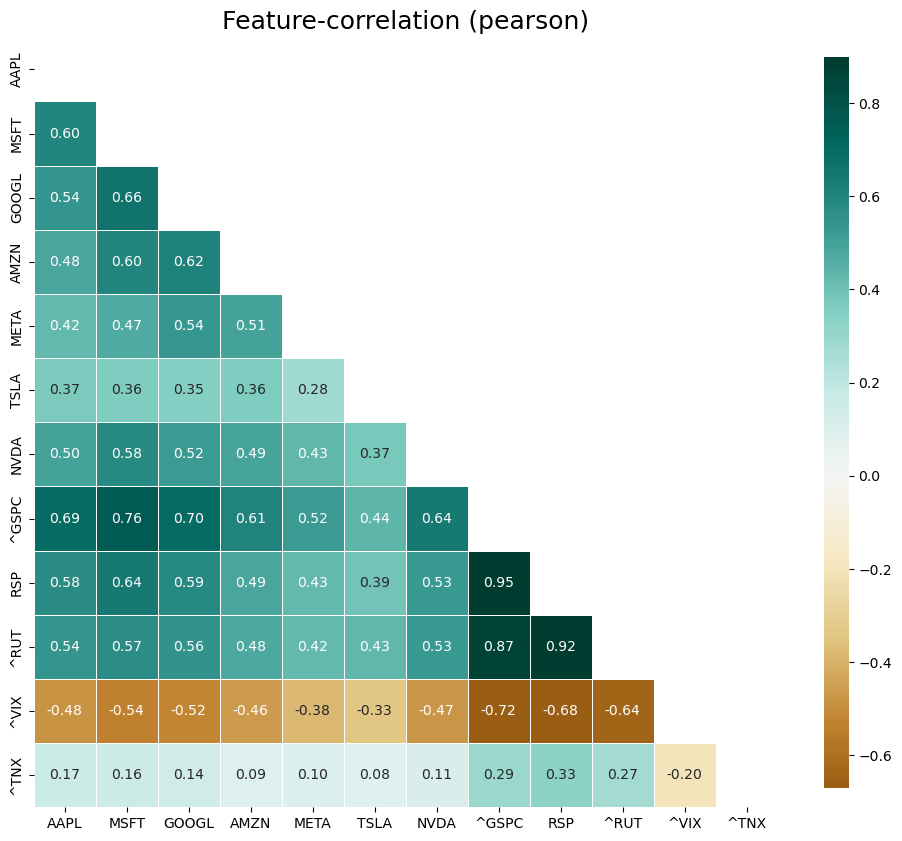

In [13]:
klib.corr_plot(returns_df)

In [14]:
klib.corr_mat(returns_df)

/opt/anaconda/envs/ml/lib/python3.12/site-packages/klib/describe.py:275: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  return corr.style.applymap(color_negative_red).format("{:.2f}", na_rep="-")


,AAPL,MSFT,GOOGL,AMZN,META,TSLA,NVDA,^GSPC,RSP,^RUT,^VIX,^TNX
AAPL,1.00,0.60,0.54,0.48,0.42,0.37,0.50,0.69,0.58,0.54,-0.48,0.17
MSFT,0.60,1.00,0.66,0.60,0.47,0.36,0.58,0.76,0.64,0.57,-0.54,0.16
GOOGL,0.54,0.66,1.00,0.62,0.54,0.35,0.52,0.70,0.59,0.56,-0.52,0.14
AMZN,0.48,0.60,0.62,1.00,0.51,0.36,0.49,0.61,0.49,0.48,-0.46,0.09
META,0.42,0.47,0.54,0.51,1.00,0.28,0.43,0.52,0.43,0.42,-0.38,0.10
TSLA,0.37,0.36,0.35,0.36,0.28,1.00,0.37,0.44,0.39,0.43,-0.33,0.08
NVDA,0.50,0.58,0.52,0.49,0.43,0.37,1.00,0.64,0.53,0.53,-0.47,0.11
^GSPC,0.69,0.76,0.70,0.61,0.52,0.44,0.64,1.00,0.95,0.87,-0.72,0.29
RSP,0.58,0.64,0.59,0.49,0.43,0.39,0.53,0.95,1.00,0.92,-0.68,0.33
^RUT,0.54,0.57,0.56,0.48,0.42,0.43,0.53,0.87,0.92,1.00,-0.64,0.27


<Axes: xlabel='^TNX', ylabel='Density'>

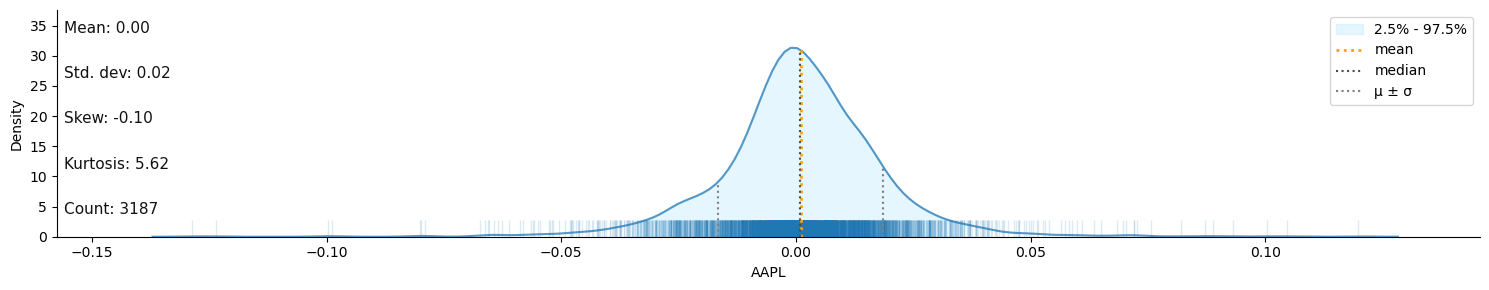

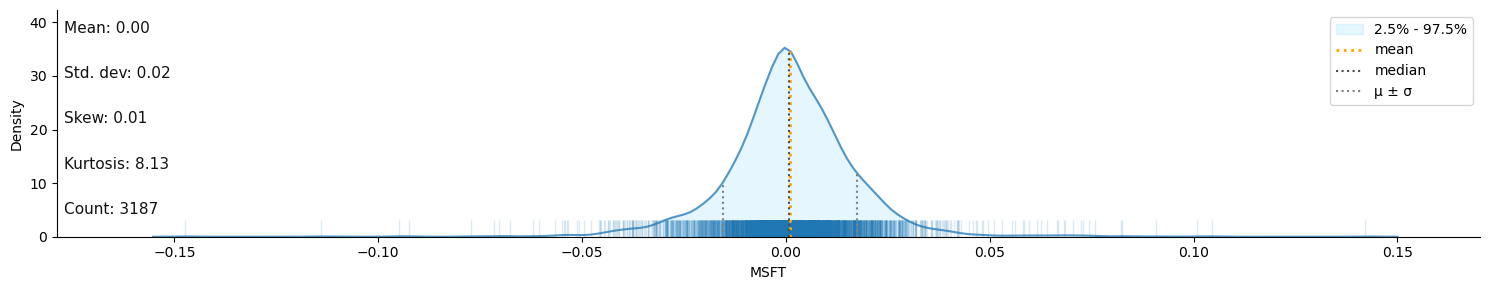

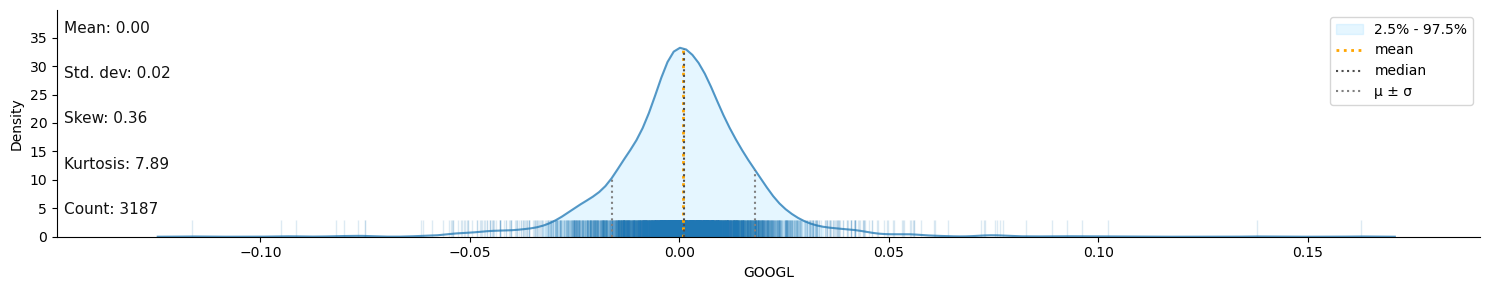

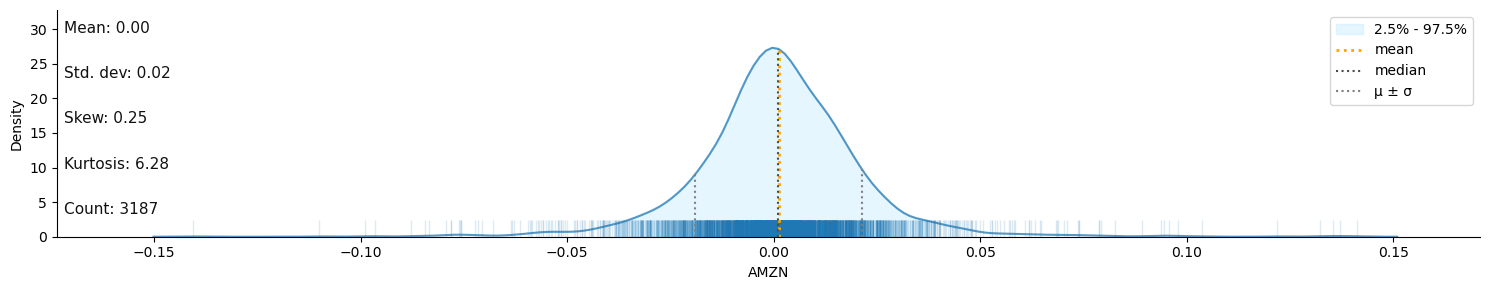

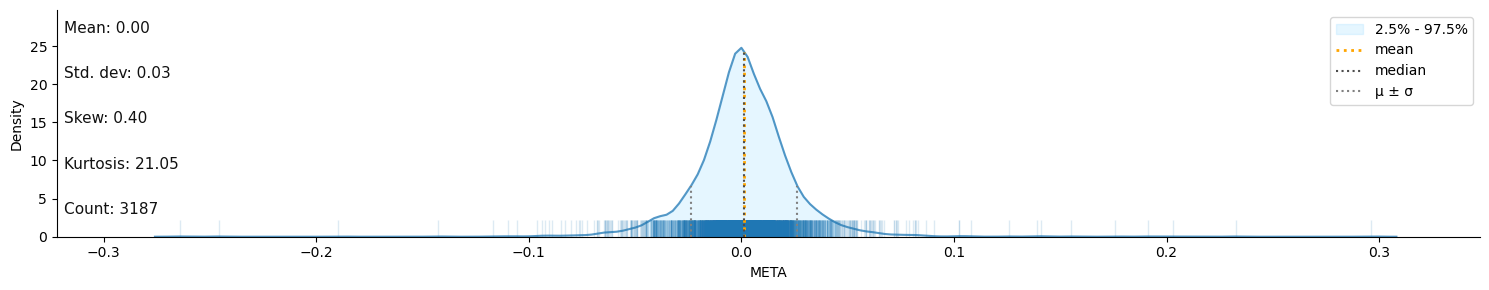

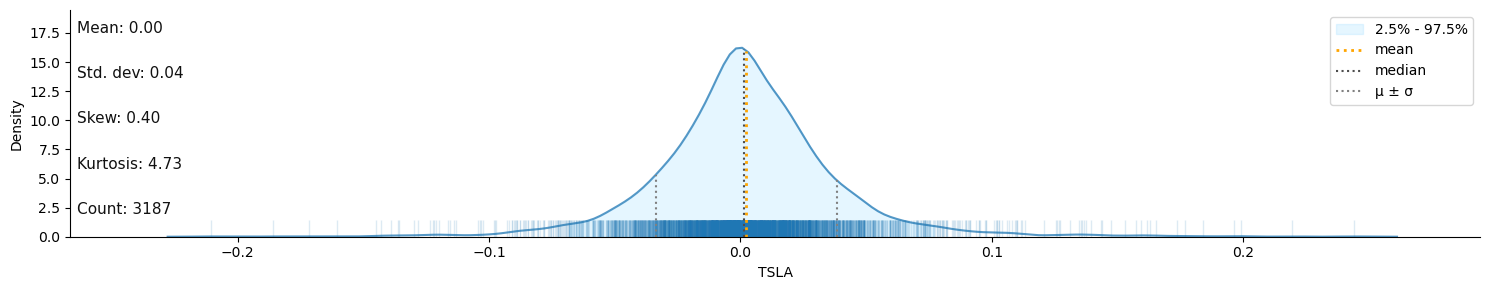

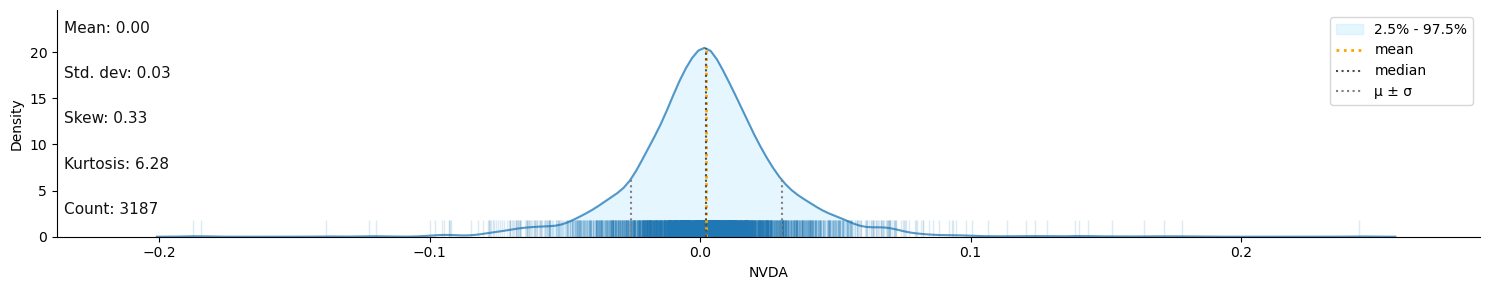

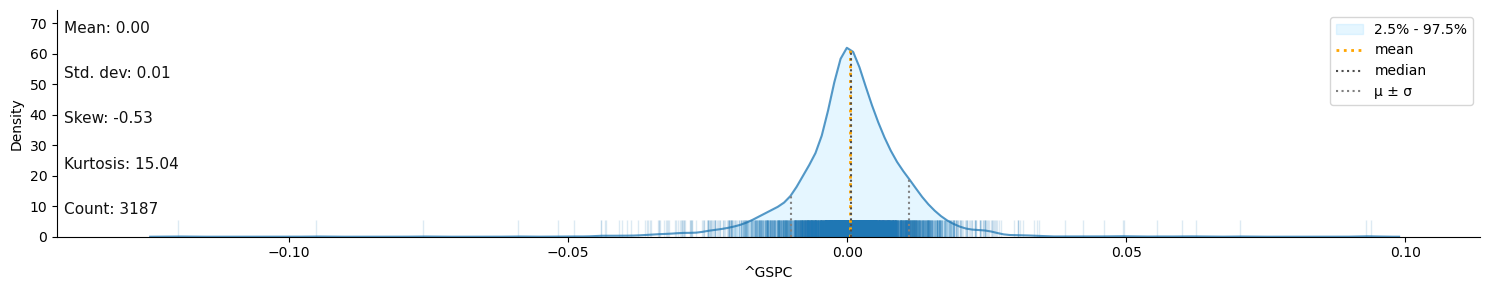

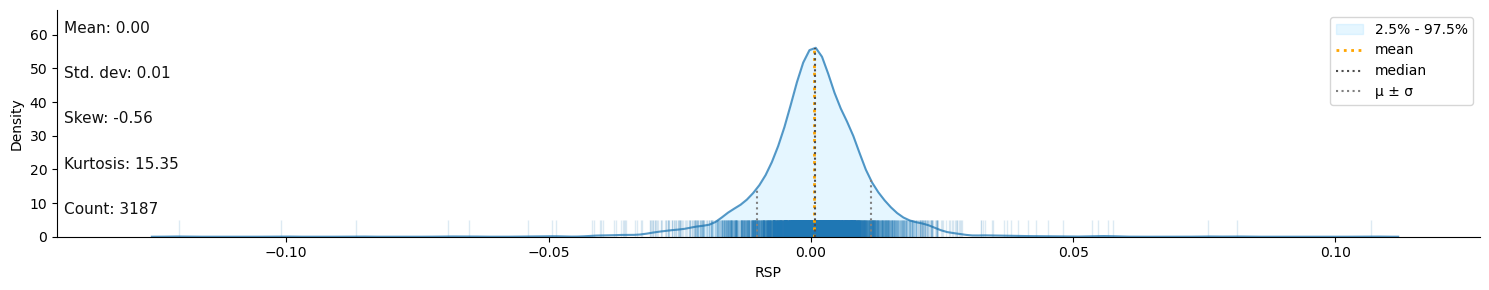

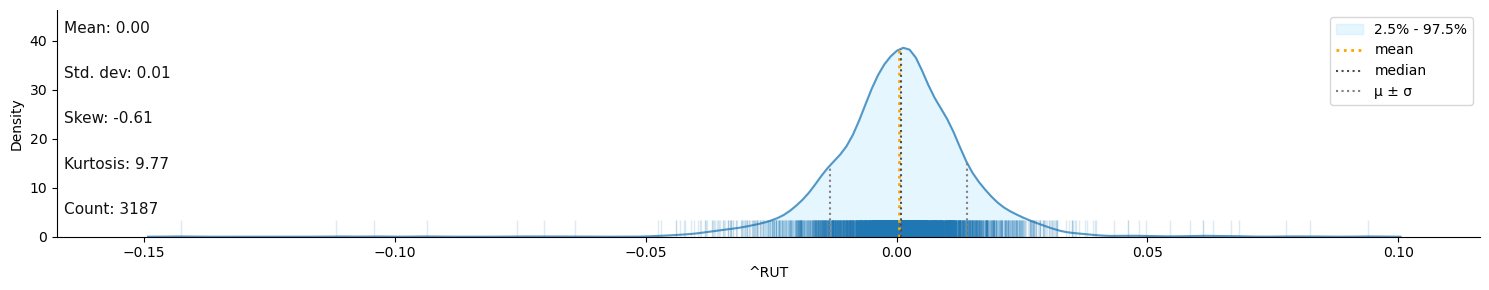

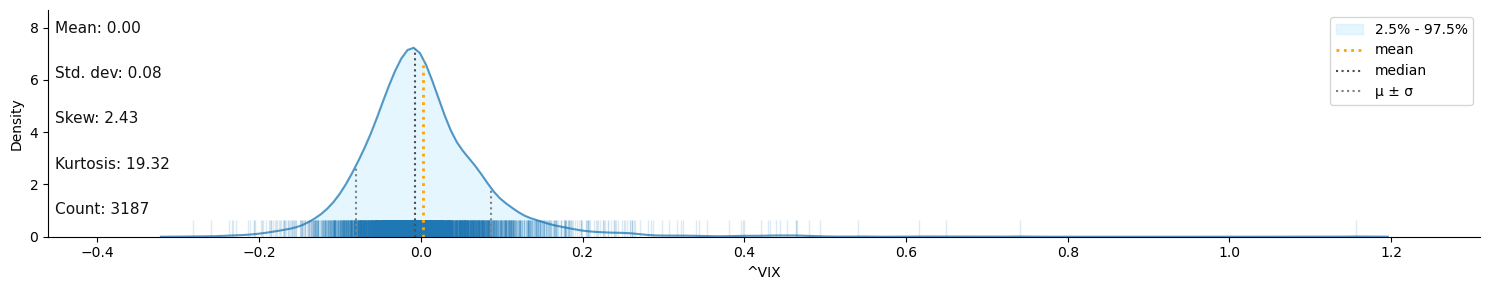

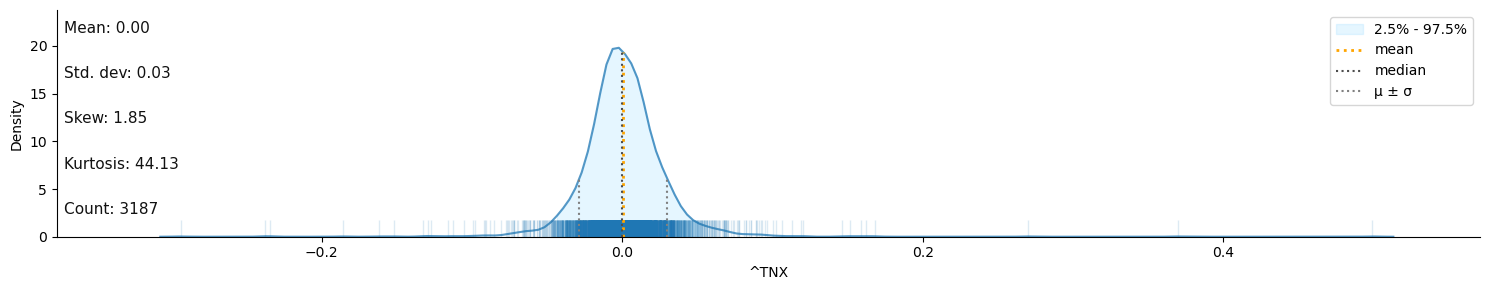

In [15]:
klib.dist_plot(returns_df)

### Regression Analysis

OLS against Indices

In [16]:
import statsmodels.formula.api as smf

def run_stock_regressions(returns_df, stock_ls, index_ls):
    # Create a dataframe to store regression results
    results_dict = {}
    
    # For each stock
    for stock in stock_ls:
        stock_results = {}
        
        # Combine stock returns with each index's returns
        stock_returns = returns_df[stock]
        
        for index in index_ls:
            index_returns = returns_df[index]
            
            # Create DataFrame with aligned dates
            regression_df = pd.DataFrame({
                'stock_returns': stock_returns,
                'index_returns': index_returns
            }).dropna()
            
            # Run regression
            model = smf.ols('stock_returns ~ index_returns', data=regression_df)
            results = model.fit()
            
            # Store key statistics
            stock_results[index] = {
                'beta': results.params['index_returns'],
                'alpha': results.params['Intercept'],
                'r_squared': results.rsquared,
                'p_value': results.pvalues['index_returns']
            }
        
        results_dict[stock] = stock_results
    
    return results_dict

# Run regressions
regression_results = run_stock_regressions(returns_df, stock_ls, index_ls)

# Display results in a readable format
for stock in stock_ls:
    print(f"\nRegression Results for {stock}:")
    print("-" * 50)
    for index in index_ls:
        results = regression_results[stock][index]
        print(f"\n{index}:")
        print(f"Beta: {results['beta']:.3f}")
        print(f"Alpha: {results['alpha']:.6f}")
        print(f"R-squared: {results['r_squared']:.3f}")
        print(f"P-value: {results['p_value']:.6f}")



Regression Results for AAPL:
--------------------------------------------------

^GSPC:
Beta: 1.159
Alpha: 0.000352
R-squared: 0.480
P-value: 0.000000

RSP:
Beta: 0.936
Alpha: 0.000467
R-squared: 0.334
P-value: 0.000000

^RUT:
Beta: 0.699
Alpha: 0.000674
R-squared: 0.292
P-value: 0.000000

^VIX:
Beta: -0.102
Alpha: 0.001291
R-squared: 0.234
P-value: 0.000000

^TNX:
Beta: 0.100
Alpha: 0.000909
R-squared: 0.028
P-value: 0.000000

Regression Results for MSFT:
--------------------------------------------------

^GSPC:
Beta: 1.193
Alpha: 0.000411
R-squared: 0.585
P-value: 0.000000

RSP:
Beta: 0.964
Alpha: 0.000529
R-squared: 0.407
P-value: 0.000000

^RUT:
Beta: 0.690
Alpha: 0.000755
R-squared: 0.327
P-value: 0.000000

^VIX:
Beta: -0.106
Alpha: 0.001379
R-squared: 0.289
P-value: 0.000000

^TNX:
Beta: 0.091
Alpha: 0.000992
R-squared: 0.027
P-value: 0.000000

Regression Results for GOOGL:
--------------------------------------------------

^GSPC:
Beta: 1.138
Alpha: 0.000341
R-squared: 0.492
P

In [17]:
# Create a function for multiple regression of indices against all stocks
def run_index_regressions_mag7(returns_df, stock_ls, index_ls):
    results_dict = {}
    
    # For each index
    for index in index_ls:
        # Create DataFrame with all stocks and the index
        regression_df = pd.DataFrame({
            'index_returns': returns_df[index],
            **{stock: returns_df[stock] for stock in stock_ls}
        }).dropna()
        
        # Create formula string for multiple regression
        formula = 'index_returns ~ ' + ' + '.join(stock_ls)
        
        # Run regression
        model = smf.ols(formula, data=regression_df)
        results = model.fit()
        
        # Store results
        results_dict[index] = {
            'coefficients': {stock: results.params[stock] for stock in stock_ls},
            'r_squared': results.rsquared,
            'adj_r_squared': results.rsquared_adj,
            'p_values': {stock: results.pvalues[stock] for stock in stock_ls},
            'f_stat': results.fvalue,
            'f_pvalue': results.f_pvalue
        }
    
    return results_dict

# Run multiple regressions
multi_regression_results = run_index_regressions_mag7(returns_df, stock_ls, index_ls)

# Display results in a readable format
for index in index_ls:
    print(f"\nMultiple Regression Results for {index}:")
    print("-" * 50)
    print(f"R-squared: {multi_regression_results[index]['r_squared']:.3f}")
    print(f"Adjusted R-squared: {multi_regression_results[index]['adj_r_squared']:.3f}")
    print(f"F-statistic: {multi_regression_results[index]['f_stat']:.3f}")
    print(f"F-statistic p-value: {multi_regression_results[index]['f_pvalue']:.6f}")
    print("\nCoefficients:")
    for stock in stock_ls:
        coef = multi_regression_results[index]['coefficients'][stock]
        p_val = multi_regression_results[index]['p_values'][stock]
        print(f"{stock:6s}: {coef:8.3f} (p-value: {p_val:.6f})")


Multiple Regression Results for ^GSPC:
--------------------------------------------------
R-squared: 0.738
Adjusted R-squared: 0.738
F-statistic: 1280.048
F-statistic p-value: 0.000000

Coefficients:
AAPL  :    0.147 (p-value: 0.000000)
MSFT  :    0.202 (p-value: 0.000000)
GOOGL :    0.117 (p-value: 0.000000)
AMZN  :    0.030 (p-value: 0.000005)
META  :    0.022 (p-value: 0.000006)
TSLA  :    0.023 (p-value: 0.000000)
NVDA  :    0.058 (p-value: 0.000000)

Multiple Regression Results for RSP:
--------------------------------------------------
R-squared: 0.515
Adjusted R-squared: 0.514
F-statistic: 482.763
F-statistic p-value: 0.000000

Coefficients:
AAPL  :    0.125 (p-value: 0.000000)
MSFT  :    0.180 (p-value: 0.000000)
GOOGL :    0.112 (p-value: 0.000000)
AMZN  :    0.003 (p-value: 0.777103)
META  :    0.015 (p-value: 0.028473)
TSLA  :    0.029 (p-value: 0.000000)
NVDA  :    0.050 (p-value: 0.000000)

Multiple Regression Results for ^RUT:
--------------------------------------------


Multiple Regression Results for S&P 500 (^GSPC):
--------------------------------------------------
R-squared: 0.973
Adjusted R-squared: 0.973
F-statistic: 14437.782
F-statistic p-value: 0.000000

Coefficients:
AAPL       :    0.062 (p-value: 0.000000)
MSFT       :    0.081 (p-value: 0.000000)
GOOGL      :    0.041 (p-value: 0.000000)
AMZN       :    0.028 (p-value: 0.000000)
META       :    0.012 (p-value: 0.000000)
TSLA       :    0.003 (p-value: 0.001819)
NVDA       :    0.025 (p-value: 0.000000)
rsp_returns:    0.674 (p-value: 0.000000)


/tmp/ipykernel_55886/3068511850.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=coef_df,


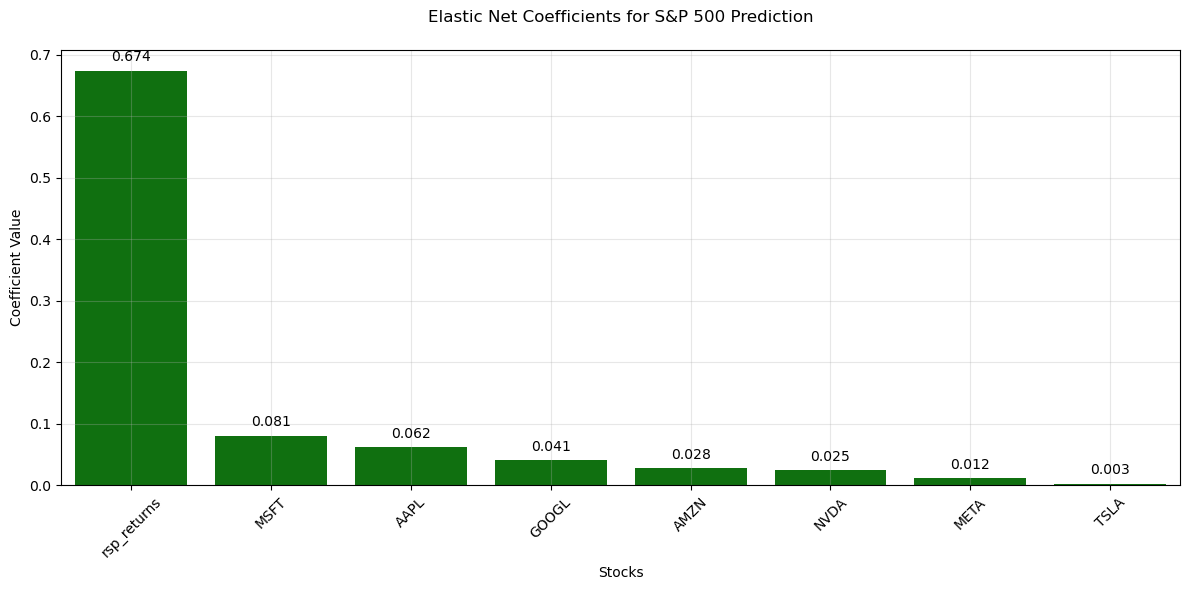

In [27]:
# Create a function for multiple regression of SP500 against Mag7 + RSP
def run_sp500_regression(returns_df, stock_ls):
    # Create DataFrame with all stocks, RSP and SP500
    regression_df = pd.DataFrame({
        'sp500_returns': returns_df['^GSPC'],
        'rsp_returns': returns_df['RSP'],
        **{stock: returns_df[stock] for stock in stock_ls}
    }).dropna()
    
    # Create formula string for multiple regression
    predictors = stock_ls + ['rsp_returns']
    formula = 'sp500_returns ~ ' + ' + '.join(predictors)
    
    # Run regression
    model = smf.ols(formula, data=regression_df)
    results = model.fit()
    
    # Store results
    results_dict = {
        'coefficients': {var: results.params[var] for var in predictors},
        'r_squared': results.rsquared,
        'adj_r_squared': results.rsquared_adj,
        'p_values': {var: results.pvalues[var] for var in predictors},
        'f_stat': results.fvalue,
        'f_pvalue': results.f_pvalue
    }
    
    return results_dict

# Run regression
sp500_results = run_sp500_regression(returns_df, stock_ls)

# Display results
print("\nMultiple Regression Results for S&P 500 (^GSPC):")
print("-" * 50)
print(f"R-squared: {sp500_results['r_squared']:.3f}")
print(f"Adjusted R-squared: {sp500_results['adj_r_squared']:.3f}")
print(f"F-statistic: {sp500_results['f_stat']:.3f}")
print(f"F-statistic p-value: {sp500_results['f_pvalue']:.6f}")
print("\nCoefficients:")
for var in sp500_results['coefficients']:
    coef = sp500_results['coefficients'][var]
    p_val = sp500_results['p_values'][var]
    print(f"{var:11s}: {coef:8.3f} (p-value: {p_val:.6f})")

coef_items = list(sp500_results['coefficients'].items())
coef_df = pd.DataFrame(coef_items, columns=['Stock', 'Coefficient'])
coef_df = coef_df.sort_values('Coefficient', key=abs, ascending=False)

# Create bar plot
plt.figure(figsize=(12, 6))
sns.barplot(data=coef_df, 
            x='Stock', 
            y='Coefficient',
            palette=['green' if x >= 0 else 'red' for x in coef_df['Coefficient']])

# Customize plot
plt.title('Elastic Net Coefficients for S&P 500 Prediction', pad=20)
plt.xlabel('Stocks')
plt.ylabel('Coefficient Value')
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)

# Add value labels on top of bars
for i, v in enumerate(coef_df['Coefficient']):
    plt.text(i, v + (0.01 if v >= 0 else -0.01), 
             f'{v:.3f}', 
             ha='center', 
             va='bottom' if v >= 0 else 'top')

plt.tight_layout()
plt.show()

In [26]:
sp500_results

{'coefficients': {'AAPL': 0.06198564246735064,
  'MSFT': 0.08102717279002905,
  'GOOGL': 0.041281996212018626,
  'AMZN': 0.028425225645581177,
  'META': 0.011772066209889128,
  'TSLA': 0.003008302958615077,
  'NVDA': 0.02469801950100893,
  'rsp_returns': 0.674434791658606},
 'r_squared': 0.9732221684679108,
 'adj_r_squared': 0.9731547604590194,
 'p_values': {'AAPL': 2.007870270769174e-136,
  'MSFT': 2.460093424162195e-147,
  'GOOGL': 1.1356516556543584e-49,
  'AMZN': 6.026948604587508e-40,
  'META': 1.7002044715382918e-14,
  'TSLA': 0.001818569150605953,
  'NVDA': 3.895378774782803e-61,
  'rsp_returns': 0.0},
 'f_stat': 14437.782460487164,
 'f_pvalue': 0.0}


Elastic Net Regression Results for ^GSPC:
--------------------------------------------------
R-squared: 0.738
Selected l1_ratio: 0.100
Selected alpha: 0.006866

Coefficients:
AAPL  :    0.146
MSFT  :    0.201
GOOGL :    0.116
AMZN  :    0.031
META  :    0.022
TSLA  :    0.022
NVDA  :    0.058

Elastic Net Regression Results for RSP:
--------------------------------------------------
R-squared: 0.514
Selected l1_ratio: 0.100
Selected alpha: 0.091030

Coefficients:
AAPL  :    0.118
MSFT  :    0.164
GOOGL :    0.106
AMZN  :    0.011
META  :    0.016
TSLA  :    0.027
NVDA  :    0.049


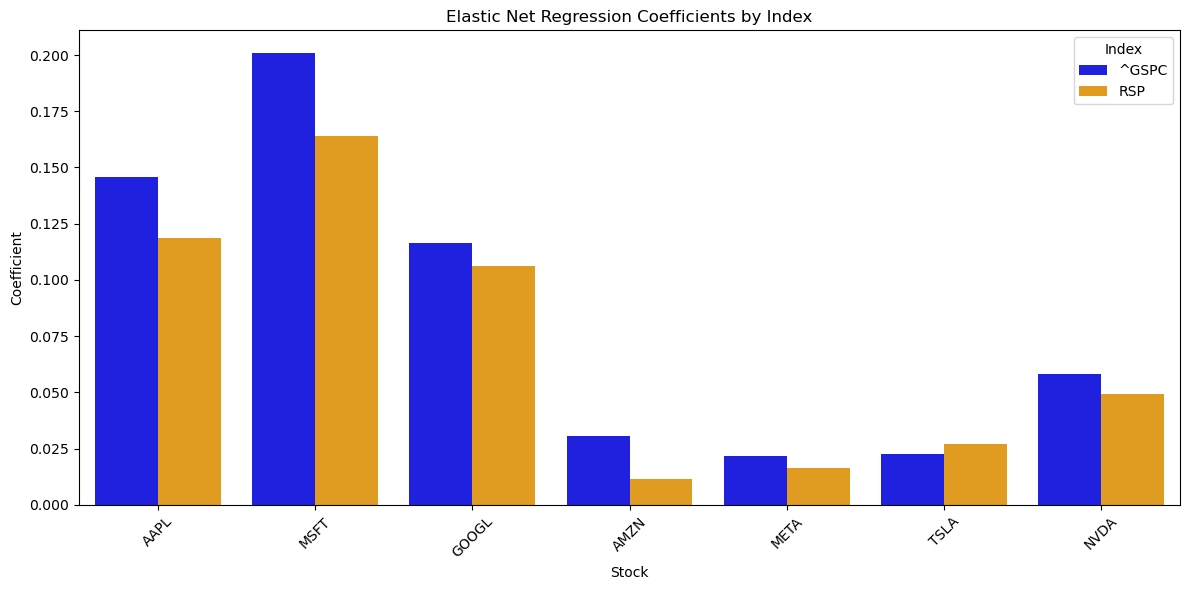

In [25]:
from sklearn.linear_model import ElasticNetCV
from sklearn.preprocessing import StandardScaler
import numpy as np

def run_elastic_net_regression(returns_df, stock_ls, target):
    # Create DataFrame with all stocks and target
    X = pd.DataFrame({stock: returns_df[stock] for stock in stock_ls}).dropna()
    y = returns_df[target].reindex(X.index)
    
    # Standardize features and target
    scaler_X = StandardScaler()
    scaler_y = StandardScaler()
    
    X_scaled = scaler_X.fit_transform(X)
    y_scaled = scaler_y.fit_transform(y.values.reshape(-1, 1)).ravel()
    
    # Create and fit ElasticNetCV
    # l1_ratio is the mixing parameter: 1 is lasso, 0 is ridge
    # Try different l1_ratios and alphas (regularization strength)
    model = ElasticNetCV(
        l1_ratio=[0.1, 0.5, 0.7, 0.9, 0.95, 0.99, 1],
        alphas=np.logspace(-4, 1, 50),
        cv=5,
        max_iter=1000,
        random_state=42
    )
    
    model.fit(X_scaled, y_scaled)
    
    # Get coefficients and transform back to original scale
    coef_scaled = model.coef_
    coef_original = coef_scaled * scaler_y.scale_[0] / scaler_X.scale_
    
    # Store results
    results = {
        'coefficients': dict(zip(stock_ls, coef_original)),
        'r_squared': model.score(X_scaled, y_scaled),
        'l1_ratio': model.l1_ratio_,
        'alpha': model.alpha_
    }
    
    return results

# Run elastic net regression for both indices
targets = ['^GSPC', 'RSP']
elastic_net_results = {}

for target in targets:
    elastic_net_results[target] = run_elastic_net_regression(returns_df, stock_ls, target)
    
    # Display results
    print(f"\nElastic Net Regression Results for {target}:")
    print("-" * 50)
    print(f"R-squared: {elastic_net_results[target]['r_squared']:.3f}")
    print(f"Selected l1_ratio: {elastic_net_results[target]['l1_ratio']:.3f}")
    print(f"Selected alpha: {elastic_net_results[target]['alpha']:.6f}")
    print("\nCoefficients:")
    for stock, coef in elastic_net_results[target]['coefficients'].items():
        print(f"{stock:6s}: {coef:8.3f}")

plt.figure(figsize=(12, 6))
coef_df = pd.DataFrame([
    {'Stock': stock, 'Coefficient': coef, 'Index': target}
    for target in targets
    for stock, coef in elastic_net_results[target]['coefficients'].items()
])

sns.barplot(data=coef_df, x='Stock', y='Coefficient', hue='Index', palette=['blue', 'orange'])
plt.xticks(rotation=45)
plt.title('Elastic Net Regression Coefficients by Index')
plt.tight_layout()
plt.show()


Elastic Net Regression Results for S&P 500 (^GSPC):
--------------------------------------------------
R-squared: 0.973
Selected l1_ratio: 0.100
Selected alpha: 0.022230

Coefficients:
AAPL  :    0.064
MSFT  :    0.083
GOOGL :    0.044
AMZN  :    0.028
META  :    0.012
TSLA  :    0.004
NVDA  :    0.026
RSP   :    0.650


/tmp/ipykernel_55886/1932310589.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=coef_df,


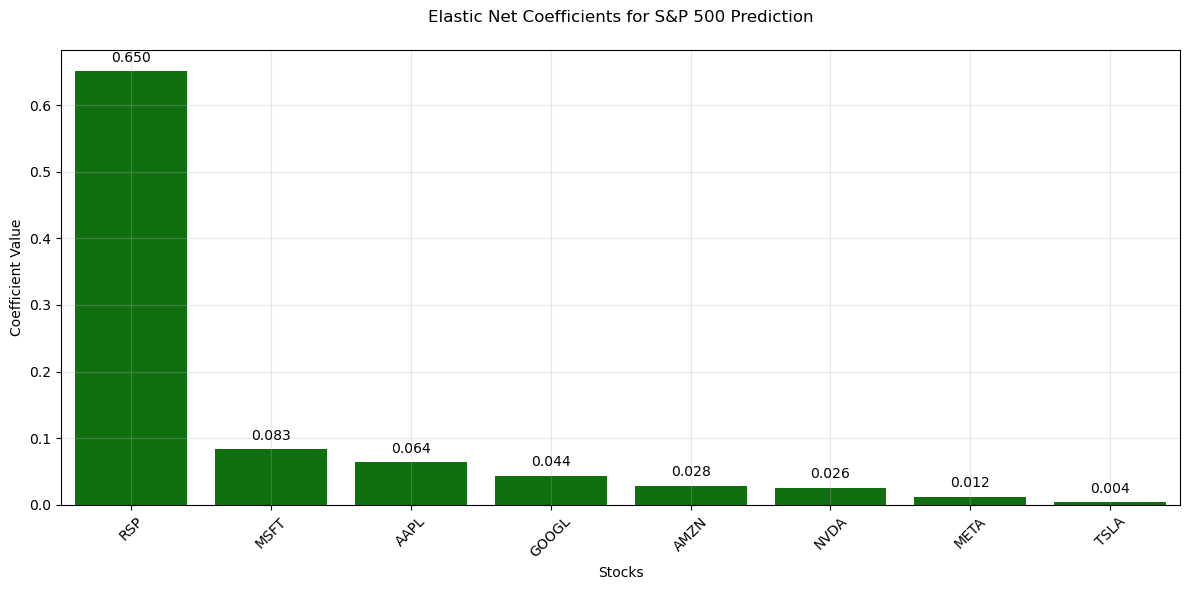

In [24]:
# Run elastic net regression for SP500 with Mag7 + RSP as predictors
def run_sp500_elastic_net(returns_df, stock_ls):
    # Create DataFrame with all stocks and RSP as predictors
    predictors = stock_ls + ['RSP']
    X = pd.DataFrame({pred: returns_df[pred] for pred in predictors}).dropna()
    y = returns_df['^GSPC'].reindex(X.index)
    
    # Standardize features and target
    scaler_X = StandardScaler()
    scaler_y = StandardScaler()
    
    X_scaled = scaler_X.fit_transform(X)
    y_scaled = scaler_y.fit_transform(y.values.reshape(-1, 1)).ravel()
    
    # Create and fit ElasticNetCV
    model = ElasticNetCV(
        l1_ratio=[0.1, 0.5, 0.7, 0.9, 0.95, 0.99, 1],
        alphas=np.logspace(-4, 1, 50),
        cv=5,
        max_iter=1000,
        random_state=42
    )
    
    model.fit(X_scaled, y_scaled)
    
    # Get coefficients and transform back to original scale
    coef_scaled = model.coef_
    coef_original = coef_scaled * scaler_y.scale_[0] / scaler_X.scale_
    
    # Store results
    results = {
        'coefficients': dict(zip(predictors, coef_original)),
        'r_squared': model.score(X_scaled, y_scaled),
        'l1_ratio': model.l1_ratio_,
        'alpha': model.alpha_
    }
    
    return results

# Run regression
sp500_elastic_results = run_sp500_elastic_net(returns_df, stock_ls)

# Display results
print("\nElastic Net Regression Results for S&P 500 (^GSPC):")
print("-" * 50)
print(f"R-squared: {sp500_elastic_results['r_squared']:.3f}")
print(f"Selected l1_ratio: {sp500_elastic_results['l1_ratio']:.3f}")
print(f"Selected alpha: {sp500_elastic_results['alpha']:.6f}")
print("\nCoefficients:")
for var, coef in sp500_elastic_results['coefficients'].items():
    print(f"{var:6s}: {coef:8.3f}")

coef_items = list(sp500_elastic_results['coefficients'].items())
coef_df = pd.DataFrame(coef_items, columns=['Stock', 'Coefficient'])
coef_df = coef_df.sort_values('Coefficient', key=abs, ascending=False)

# Create bar plot
plt.figure(figsize=(12, 6))
sns.barplot(data=coef_df, 
            x='Stock', 
            y='Coefficient',
            palette=['green' if x >= 0 else 'red' for x in coef_df['Coefficient']])

# Customize plot
plt.title('Elastic Net Coefficients for S&P 500 Prediction', pad=20)
plt.xlabel('Stocks')
plt.ylabel('Coefficient Value')
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)

# Add value labels on top of bars
for i, v in enumerate(coef_df['Coefficient']):
    plt.text(i, v + (0.01 if v >= 0 else -0.01), 
             f'{v:.3f}', 
             ha='center', 
             va='bottom' if v >= 0 else 'top')

plt.tight_layout()
plt.show()

In [ ]:
# Convert coefficients to DataFrame for easier plotting with seaborn


### Non Linear Regression


XGBoost Results for ^GSPC:
--------------------------------------------------
Train R-squared: 0.845
Test R-squared: 0.729
Train RMSE: 0.004221
Test RMSE: 0.005077

Feature Importance:
GOOGL : 0.3566
MSFT  : 0.3073
AAPL  : 0.1499
NVDA  : 0.0613
AMZN  : 0.0498
META  : 0.0429
TSLA  : 0.0322

XGBoost Results for RSP:
--------------------------------------------------
Train R-squared: 0.715
Test R-squared: 0.371
Train RMSE: 0.005978
Test RMSE: 0.007623

Feature Importance:
GOOGL : 0.3289
MSFT  : 0.2923
AAPL  : 0.1360
NVDA  : 0.0939
TSLA  : 0.0687
META  : 0.0541
AMZN  : 0.0262


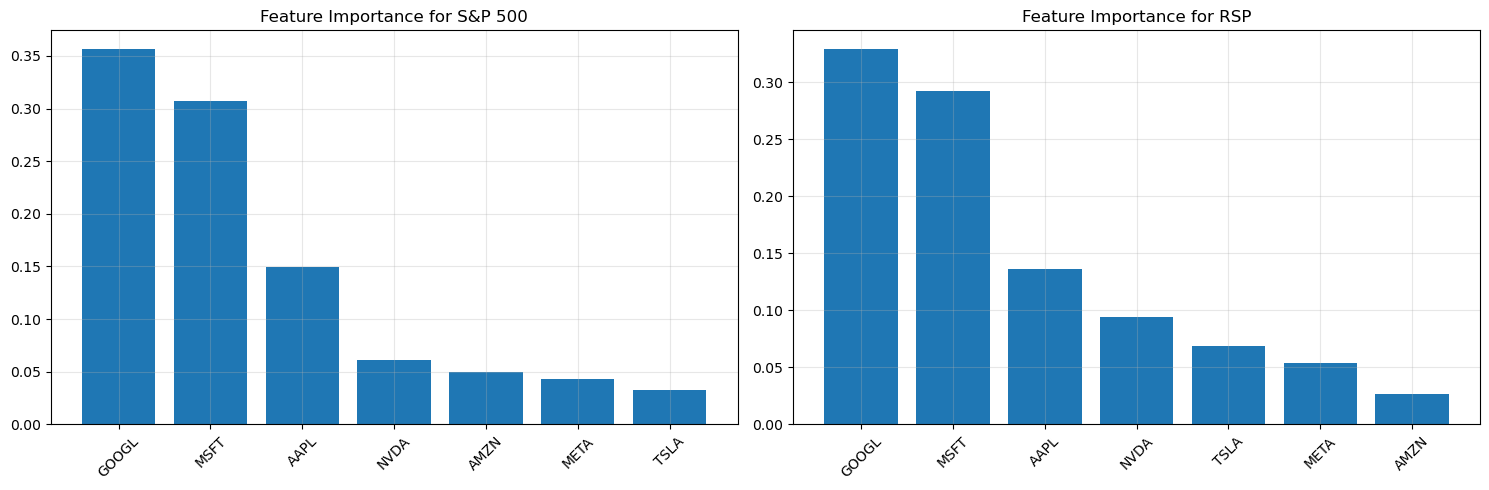

In [23]:
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

def run_xgboost_regression(returns_df, stock_ls, target):
    # Prepare data
    X = returns_df[stock_ls].dropna()
    y = returns_df[target].reindex(X.index)
    
    # Split data
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, shuffle=False
    )
    
    # Create and train model
    model = xgb.XGBRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )
    
    model.fit(X_train, y_train)
    
    # Make predictions
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)
    
    # Calculate metrics
    results = {
        'train_r2': r2_score(y_train, y_pred_train),
        'test_r2': r2_score(y_test, y_pred_test),
        'train_rmse': np.sqrt(mean_squared_error(y_train, y_pred_train)),
        'test_rmse': np.sqrt(mean_squared_error(y_test, y_pred_test)),
        'feature_importance': dict(zip(stock_ls, model.feature_importances_))
    }
    
    return results, model

# Run XGBoost for both S&P 500 and RSP
targets = ['^GSPC', 'RSP']
xgb_results = {}
xgb_models = {}

for target in targets:
    xgb_results[target], xgb_models[target] = run_xgboost_regression(returns_df, stock_ls, target)
    
    print(f"\nXGBoost Results for {target}:")
    print("-" * 50)
    print(f"Train R-squared: {xgb_results[target]['train_r2']:.3f}")
    print(f"Test R-squared: {xgb_results[target]['test_r2']:.3f}")
    print(f"Train RMSE: {xgb_results[target]['train_rmse']:.6f}")
    print(f"Test RMSE: {xgb_results[target]['test_rmse']:.6f}")
    print("\nFeature Importance:")
    
    # Sort feature importance
    importance = xgb_results[target]['feature_importance']
    sorted_importance = dict(sorted(importance.items(), key=lambda x: x[1], reverse=True))
    
    for stock, imp in sorted_importance.items():
        print(f"{stock:6s}: {imp:.4f}")

# Plot feature importance
plt.figure(figsize=(15, 5))

# S&P 500 feature importance
plt.subplot(1, 2, 1)
importance_sp500 = xgb_results['^GSPC']['feature_importance']
sorted_importance_sp500 = dict(sorted(importance_sp500.items(), key=lambda x: x[1], reverse=True))
plt.bar(range(len(sorted_importance_sp500)), list(sorted_importance_sp500.values()))
plt.xticks(range(len(sorted_importance_sp500)), list(sorted_importance_sp500.keys()), rotation=45)
plt.title('Feature Importance for S&P 500')
plt.grid(True, alpha=0.3)

# RSP feature importance
plt.subplot(1, 2, 2)
importance_rsp = xgb_results['RSP']['feature_importance']
sorted_importance_rsp = dict(sorted(importance_rsp.items(), key=lambda x: x[1], reverse=True))
plt.bar(range(len(sorted_importance_rsp)), list(sorted_importance_rsp.values()))
plt.xticks(range(len(sorted_importance_rsp)), list(sorted_importance_rsp.keys()), rotation=45)
plt.title('Feature Importance for RSP')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Scatter Plots & Returns Time Series

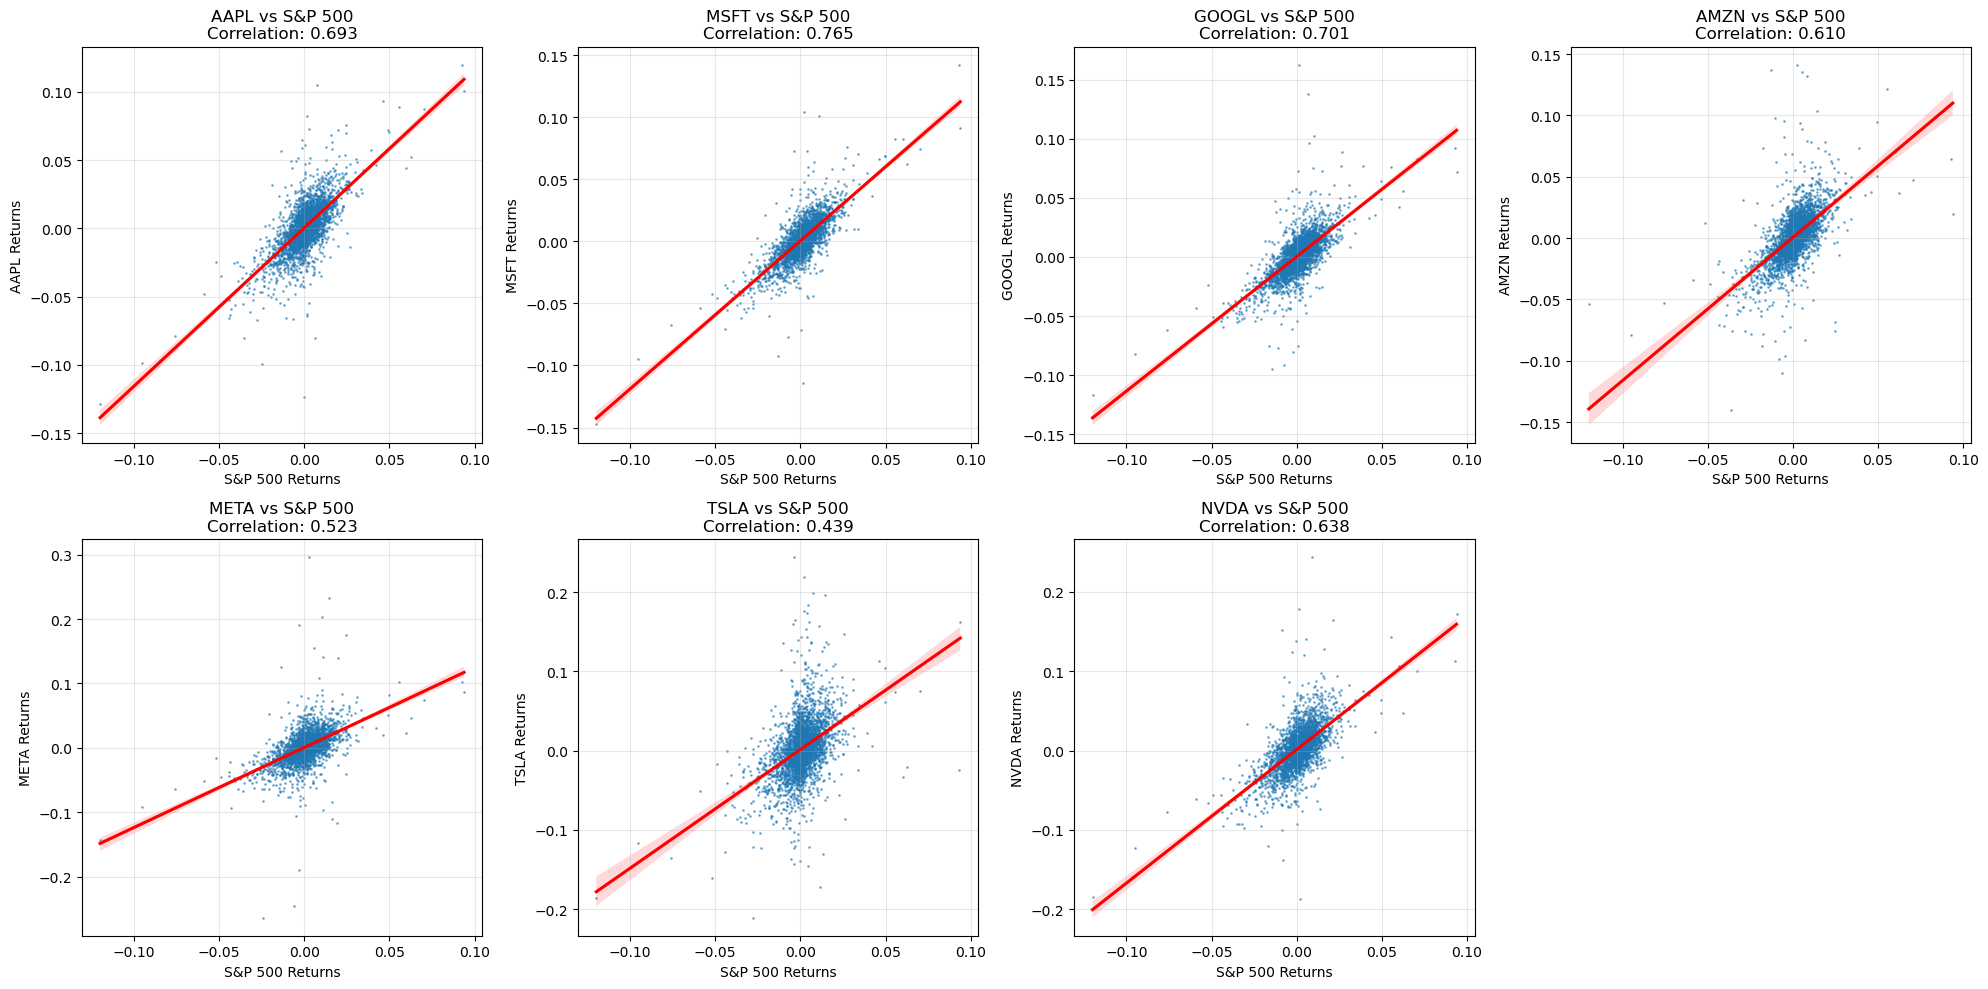

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set up the figure with subplots
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.ravel()

# Create scatter plots for each stock
for i, stock in enumerate(stock_ls):
    # Get data
    stock_returns = returns_df[stock]
    sp500_returns = returns_df['^GSPC']
    
    # Create DataFrame with aligned dates
    plot_df = pd.DataFrame({
        'SP500': sp500_returns,
        'Stock': stock_returns
    }).dropna()
    
    # Calculate correlation
    corr = plot_df.corr().iloc[0,1]
    
    # Create scatter plot
    sns.regplot(
        data=plot_df,
        x='SP500',
        y='Stock',
        ax=axes[i],
        scatter_kws={'alpha':0.5, 's':1},
        line_kws={'color': 'red'}
    )
    
    # Customize plot
    axes[i].set_title(f'{stock} vs S&P 500\nCorrelation: {corr:.3f}')
    axes[i].set_xlabel('S&P 500 Returns')
    axes[i].set_ylabel(f'{stock} Returns')
    
    # Add grid
    axes[i].grid(True, alpha=0.3)

# Remove the last empty subplot
if len(stock_ls) < 8:
    fig.delaxes(axes[7])

# Adjust layout
plt.tight_layout()
plt.show()

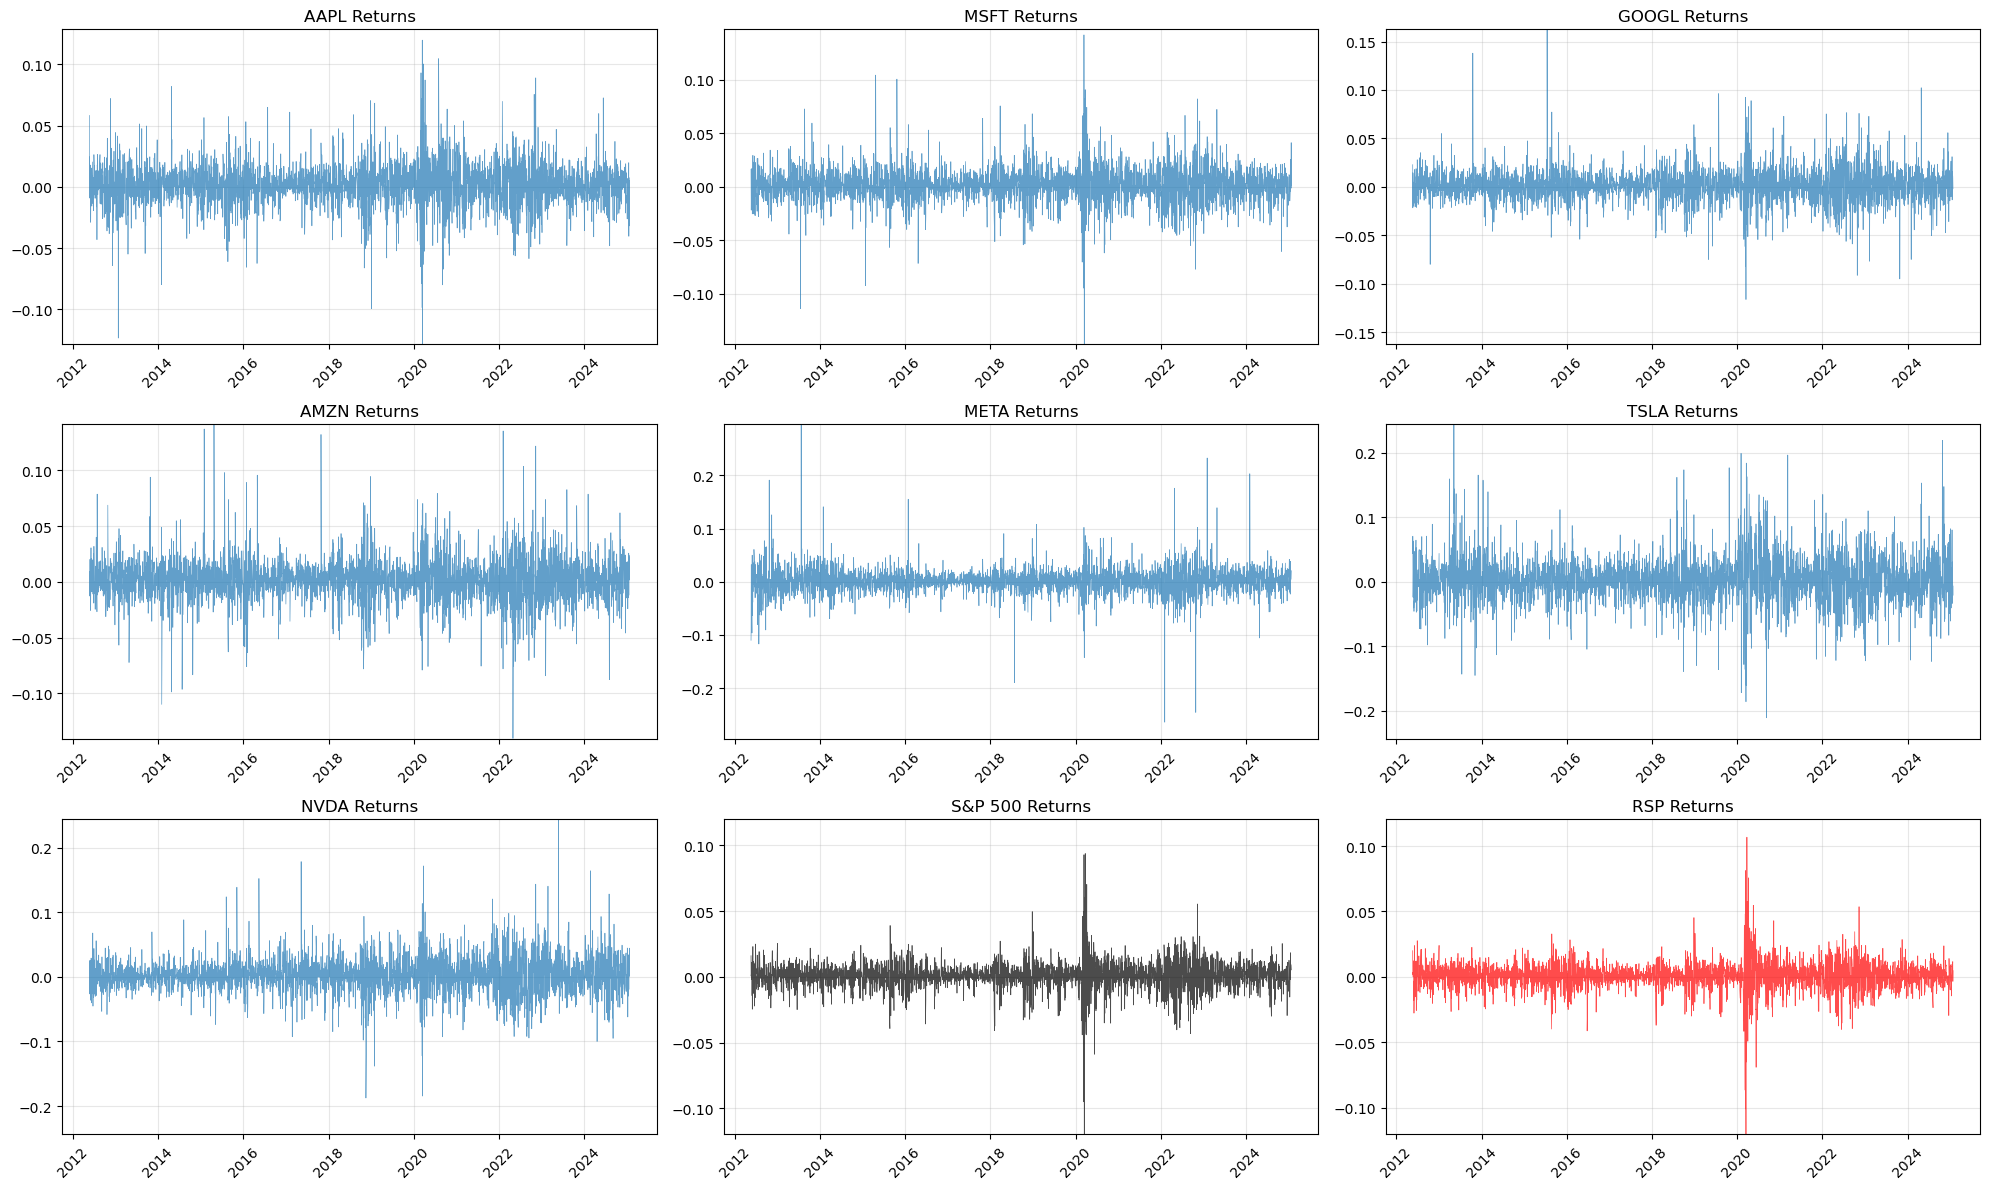

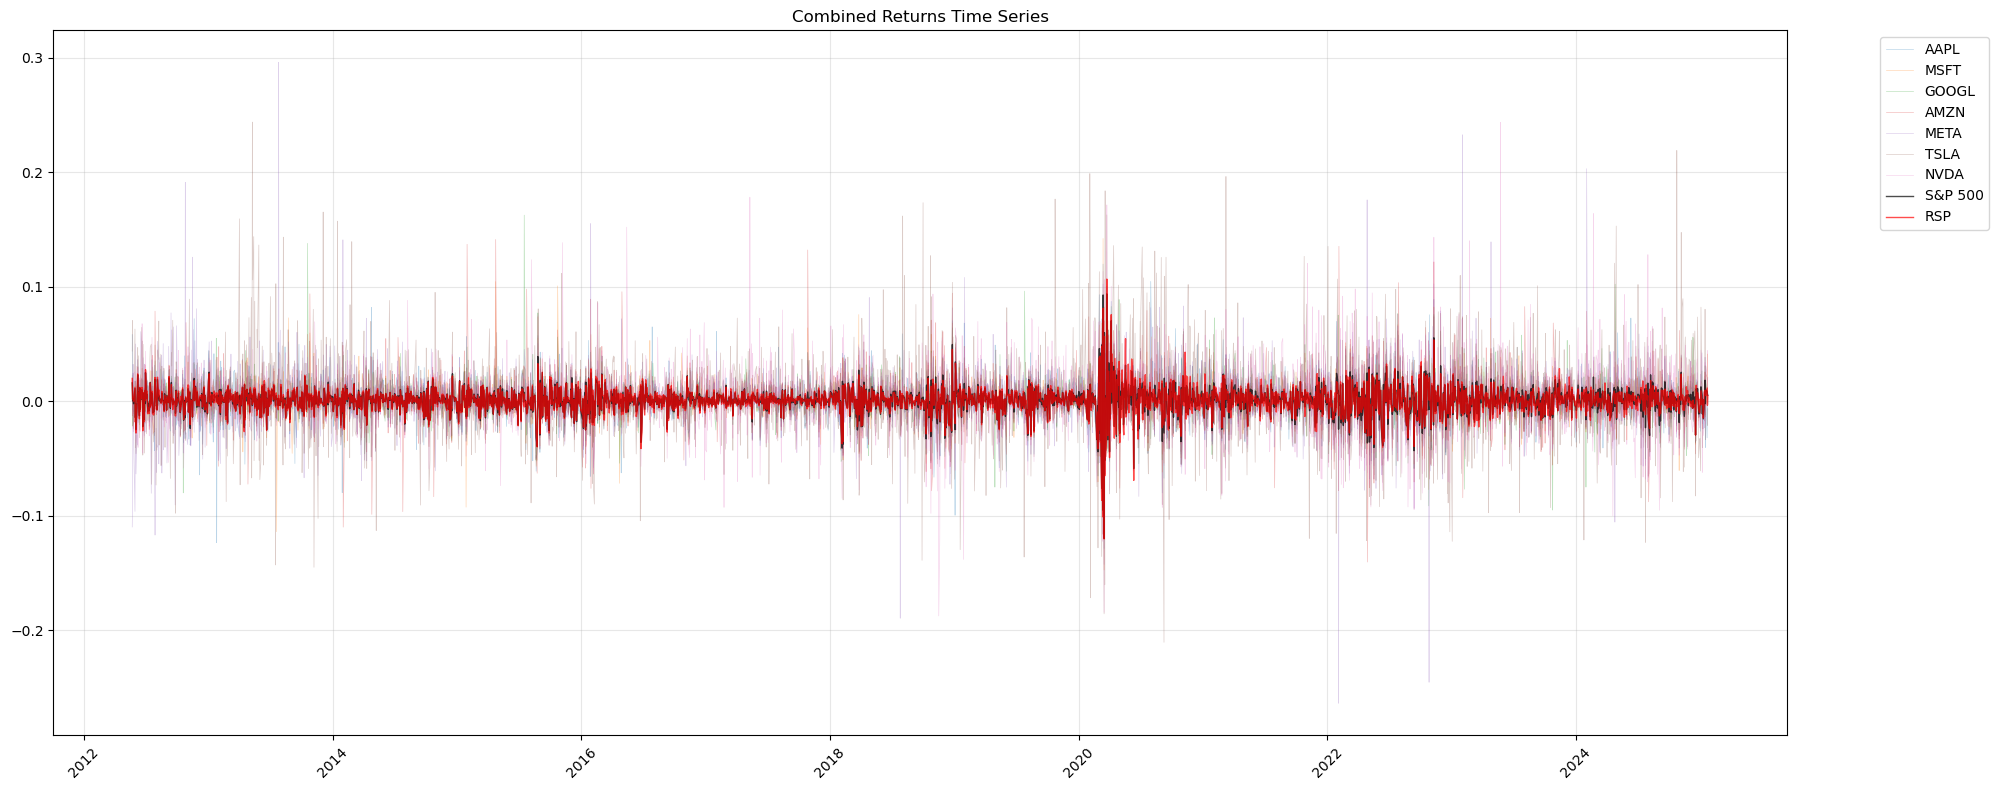

In [22]:
# Create time series plots
plt.figure(figsize=(20, 12))

# Plot stocks
for i, stock in enumerate(stock_ls):
    plt.subplot(3, 3, i+1)
    plt.plot(returns_df.index, returns_df[stock], alpha=0.7, linewidth=0.5)
    plt.title(f'{stock} Returns')
    plt.grid(True, alpha=0.3)
    plt.xticks(rotation=45)
    # Set y-axis limits to be symmetric around 0
    ylim = max(abs(returns_df[stock].min()), abs(returns_df[stock].max()))
    plt.ylim(-ylim, ylim)

# Plot S&P 500
plt.subplot(3, 3, 8)
plt.plot(returns_df.index, returns_df['^GSPC'], 'k-', alpha=0.7, linewidth=0.5)
plt.title('S&P 500 Returns')
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
# Set y-axis limits to be symmetric around 0
ylim = max(abs(returns_df['^GSPC'].min()), abs(returns_df['^GSPC'].max()))
plt.ylim(-ylim, ylim)

# Plot RSP
plt.subplot(3, 3, 9)
plt.plot(returns_df.index, returns_df['RSP'], 'r-', alpha=0.7, linewidth=0.5)
plt.title('RSP Returns')
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
# Set y-axis limits to be symmetric around 0
ylim = max(abs(returns_df['RSP'].min()), abs(returns_df['RSP'].max()))
plt.ylim(-ylim, ylim)

plt.tight_layout()
plt.show()

# Create a combined plot with all series
plt.figure(figsize=(20, 8))
for stock in stock_ls:
    plt.plot(returns_df.index, returns_df[stock], alpha=0.3, linewidth=0.5, label=stock)
plt.plot(returns_df.index, returns_df['^GSPC'], 'k-', alpha=0.7, linewidth=1, label='S&P 500')
plt.plot(returns_df.index, returns_df['RSP'], 'r-', alpha=0.7, linewidth=1, label='RSP')
plt.title('Combined Returns Time Series')
plt.grid(True, alpha=0.3)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()